In [3]:
!pip install albumentations opencv-python-headless

In [4]:
import cv2
import os
import albumentations as A
import numpy as np
import shutil
from google.colab import files

video_files = {
    'bottle': 'bottle.mp4',
    'cup': 'cup.mp4',
    'keys': 'keys.mp4',
    'pen': 'pen.mp4'
}

raw_output_dir = 'extracted_raw_frames'
aug_output_dir = 'extracted_artaug_frames'

art_aug_transform = A.Compose([
    A.MotionBlur(blur_limit=(7, 15), p=0.7),
    A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=0.8),
    A.GaussNoise(var_limit=(10.0, 40.0), p=0.5)
])

for class_name, video_path in video_files.items():
    raw_class_dir = os.path.join(raw_output_dir, class_name)
    aug_class_dir = os.path.join(aug_output_dir, class_name)
    os.makedirs(raw_class_dir, exist_ok=True)
    os.makedirs(aug_class_dir, exist_ok=True)

    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print(f"⚠️ Ошибка открытия {video_path}")
        continue

    count = 0
    saved_count = 0

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break

        if count % 10 == 0:
            raw_filename = os.path.join(raw_class_dir, f"{class_name}_raw_{saved_count:03d}.jpg")
            cv2.imwrite(raw_filename, frame)

            img_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            augmented = art_aug_transform(image=img_rgb)['image']
            aug_bgr = cv2.cvtColor(augmented, cv2.COLOR_RGB2BGR)

            aug_filename = os.path.join(aug_class_dir, f"{class_name}_artaug_{saved_count:03d}.jpg")
            cv2.imwrite(aug_filename, aug_bgr)

            saved_count += 1
        count += 1

    cap.release()
    print(f"✅ Для класса '{class_name}' создано {saved_count} обычных и {saved_count} ArtAug кадров.")

print("\n📦 Упаковка кадров в ZIP-архив...")
shutil.make_archive('new_artaug_dataset', 'zip', aug_output_dir)
files.download('new_artaug_dataset.zip')
print("🚀 Архив 'new_artaug_dataset.zip' сейчас начнет скачиваться!")

⚠️ Ошибка открытия bottle.mp4
⚠️ Ошибка открытия cup.mp4
⚠️ Ошибка открытия keys.mp4
⚠️ Ошибка открытия pen.mp4

📦 Упаковка кадров в ZIP-архив...


/tmp/ipykernel_841/4144211376.py:21: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(10.0, 40.0), p=0.5)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

🚀 Архив 'new_artaug_dataset.zip' сейчас начнет скачиваться!


In [5]:
!nvidia-smi

Fri Nov  6 17:18:31 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   54C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [6]:
!pip install ultralytics roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="DtW5ilo5BOBDsXbimAn4")
project = rf.workspace("s-workspace-bqdmg").project("my-first-project-u8w9b")
version = project.version(1)
dataset = version.download("yolov11")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 63.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 112.7 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [ultralytics]
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to My-First-Project-1 in yolov11:: 100%|██████████| 262/262 [00:00<00:00, 1867.80it/s]


In [7]:
from ultralytics import YOLO

# Загружаем предобученную модель YOLO11
model = YOLO('yolo11n.pt')

# Запускаем обучение на 50 эпох
results = model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=50,
    imgsz=512,
    plots=True
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/My-First-Project-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fractio

In [8]:
import time

# Точность mAP@0.5
metrics = model.val()
print(f"mAP@0.5: {metrics.box.map50:.4f}")
print(f"mAP@0.5:0.95: {metrics.box.map:.4f}")

# Скорость (FPS)
start_time = time.time()
test_results = model.predict(source=f"{dataset.location}/test/images", save=True)
total_time = time.time() - start_time
total_images = len(test_results)
fps = total_images / total_time

print(f"Обработано изображений: {total_images}")
print(f"Средняя скорость inference (FPS): {fps:.2f}")

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2971.9±791.7 MB/s, size: 85.2 KB)
val: Scanning /content/My-First-Project-1/valid/labels.cache... 25 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 25/25 7.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.4it/s 0.8s
                   all         25         25      0.825      0.957       0.97      0.895
                bottle          2          2      0.591          1      0.995      0.995
                   cup          7          7      0.855      0.857      0.924      0.897
                  keys         10         10      0.906       0.97      0.968      0.741
                   pen          6          6      0.949          1      0.995      0.945
Speed: 2.1ms preprocess, 14.1ms inferenc

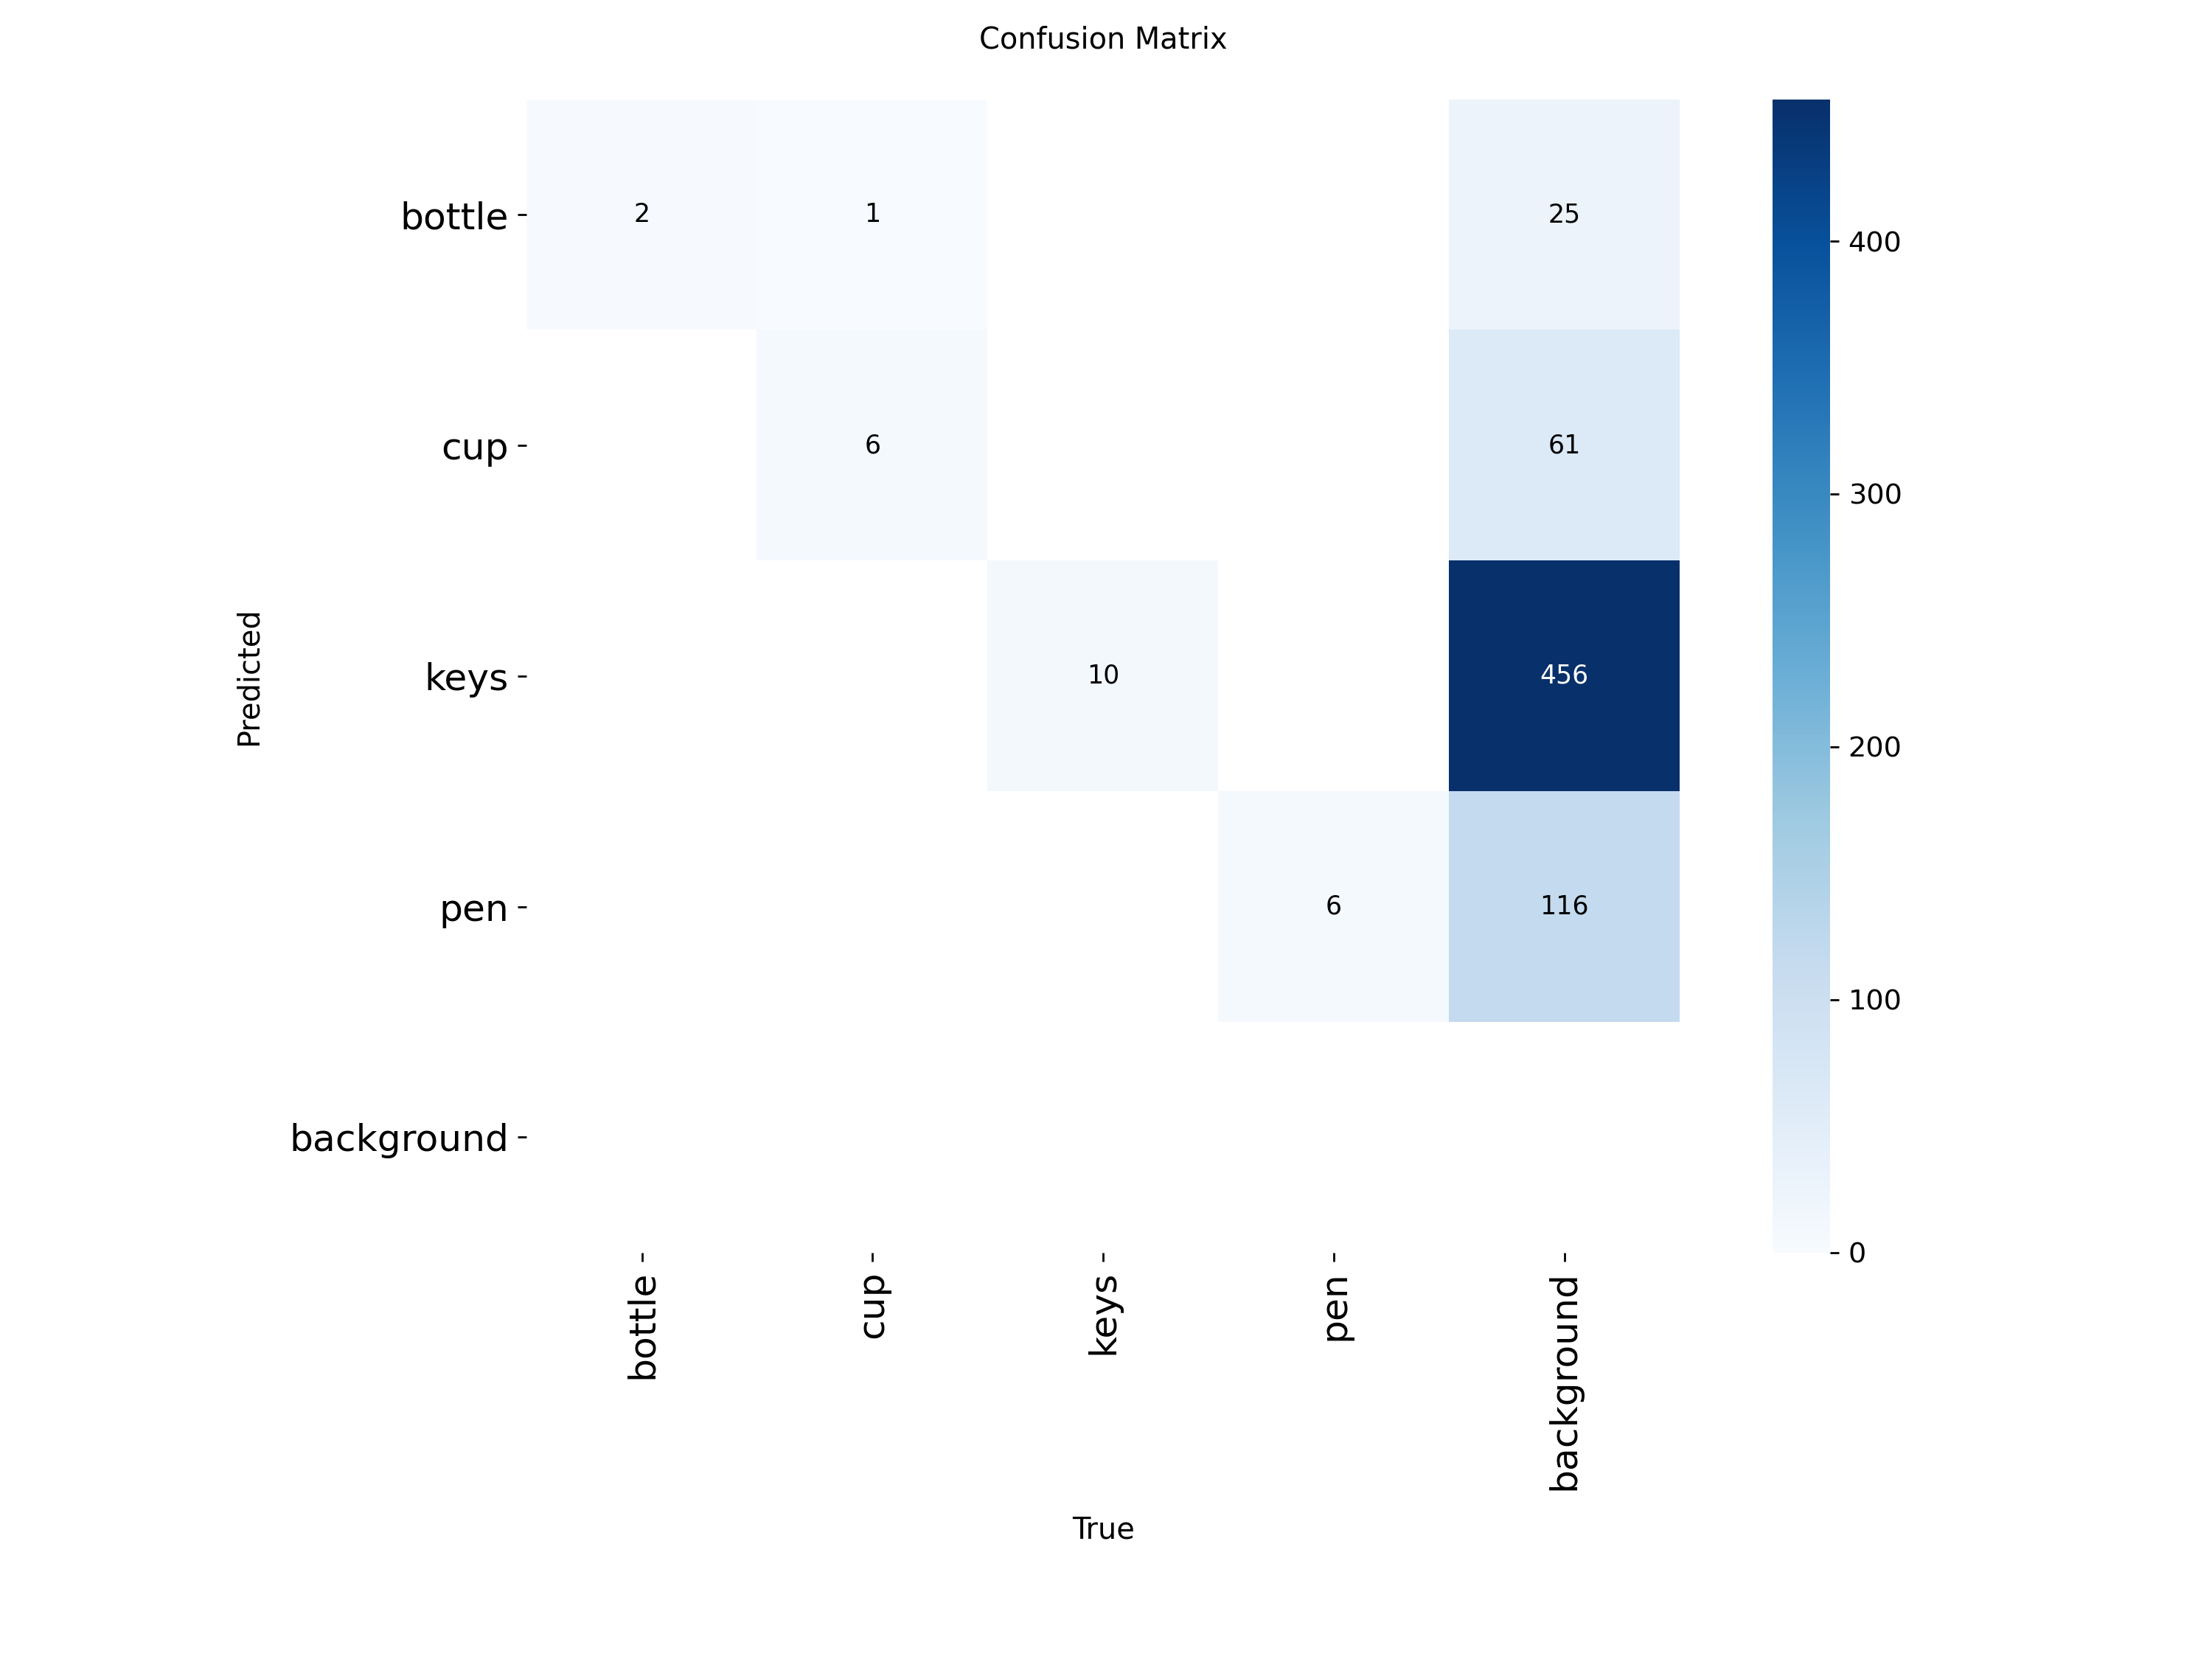

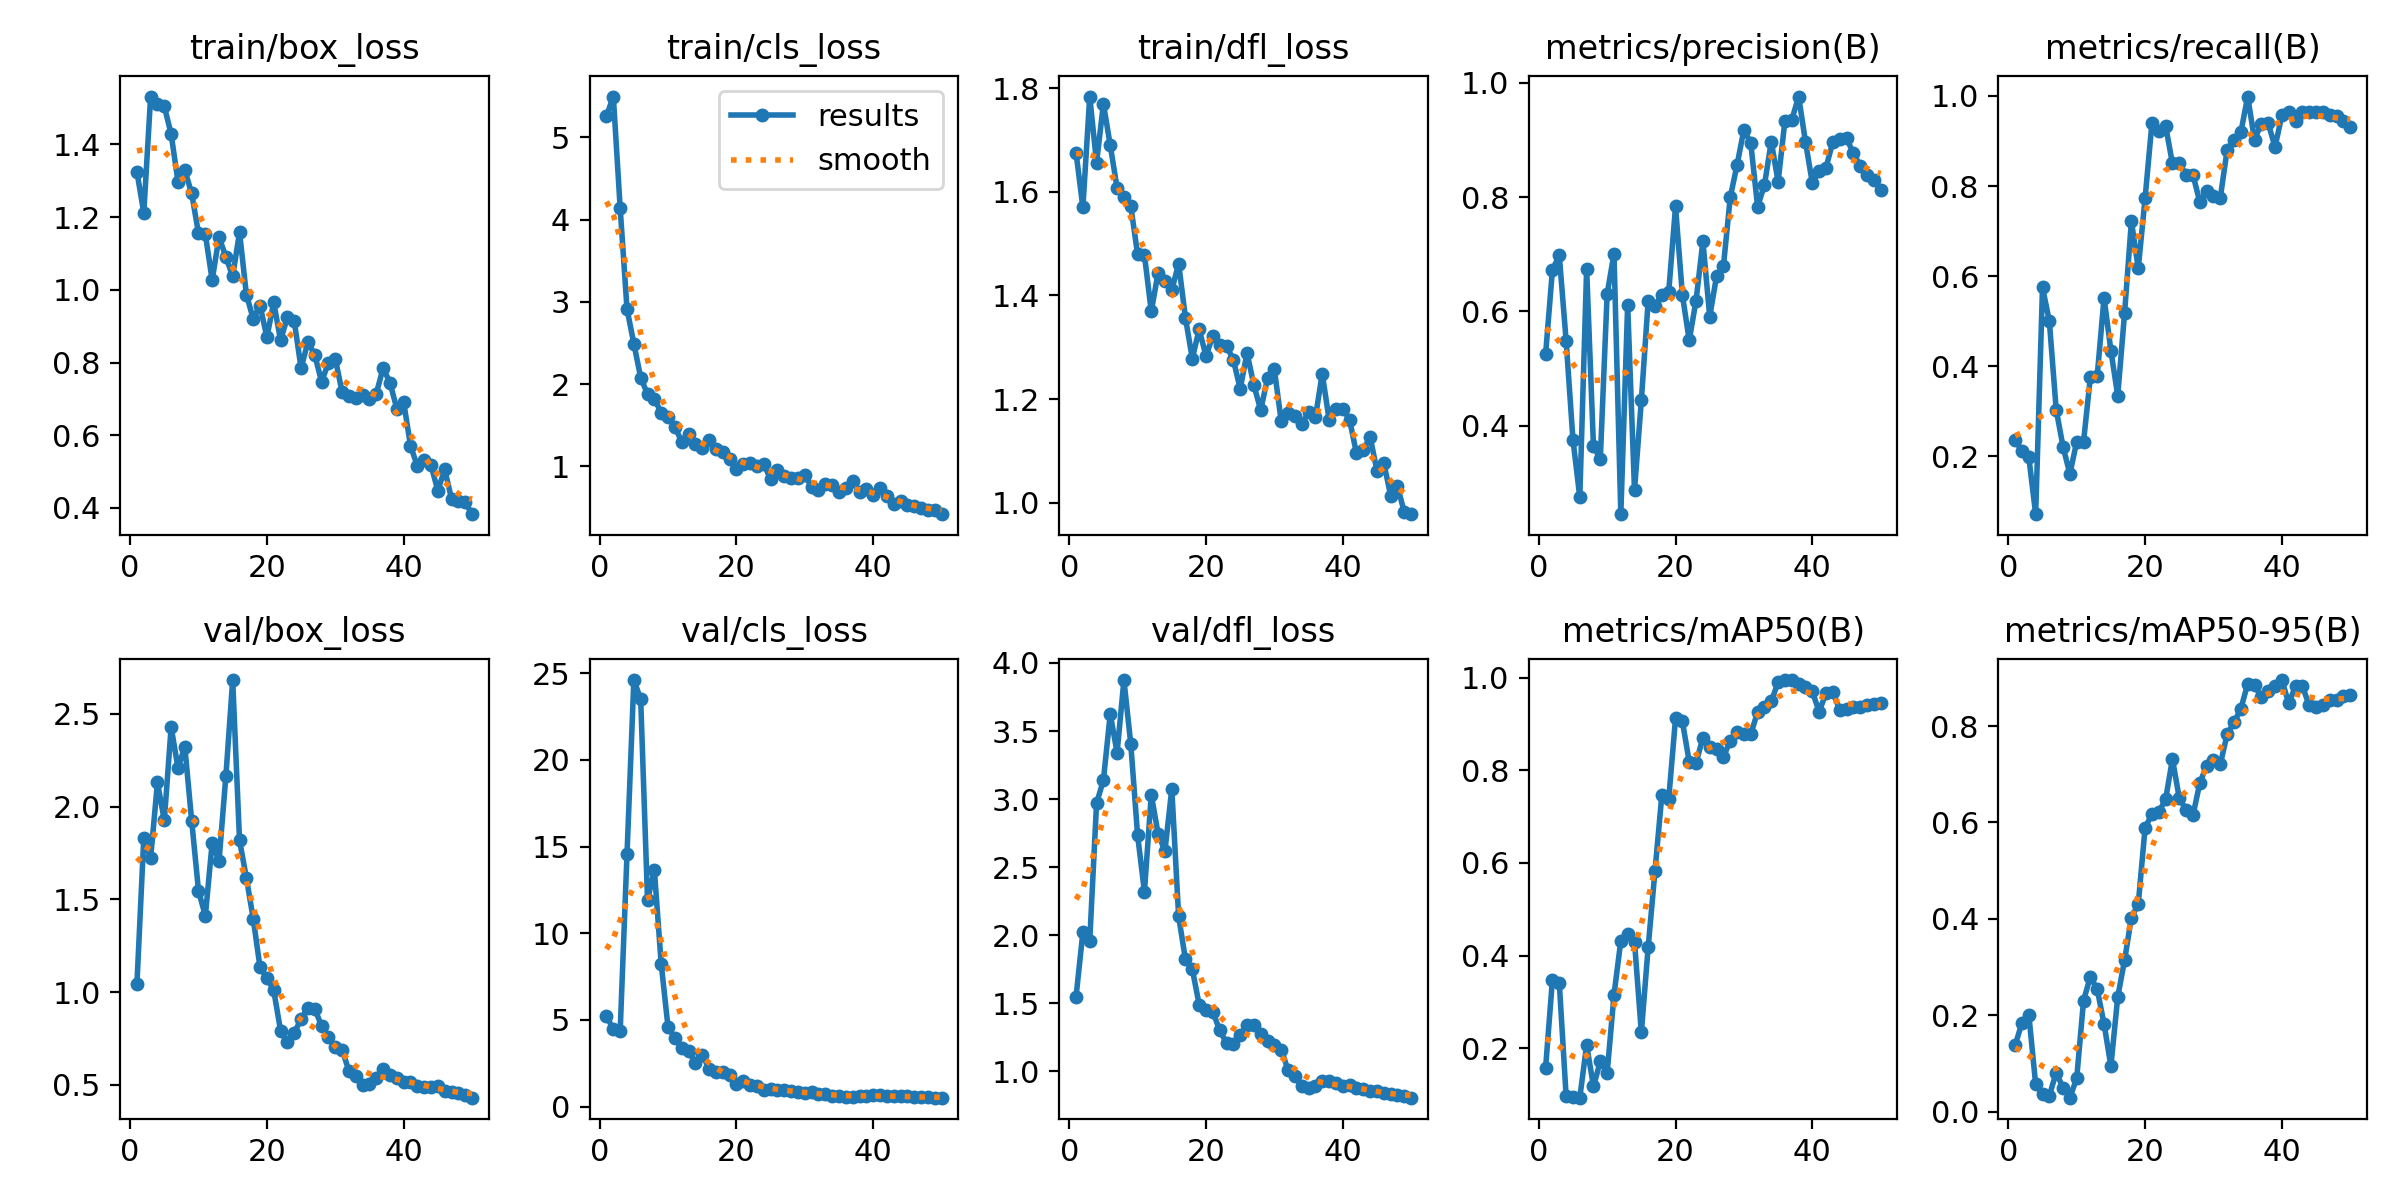

In [9]:
from IPython.display import Image, display

display(Image(filename='runs/detect/train/confusion_matrix.png'))
display(Image(filename='runs/detect/train/results.png'))

In [10]:
!pip install gradio yolo-gradcam

ERROR: Could not find a version that satisfies the requirement yolo-gradcam (from versions: none)
ERROR: No matching distribution found for yolo-gradcam


In [11]:
!pip install gradio

In [ ]:
import gradio as gr
import cv2
import numpy as np
import time
from ultralytics import YOLO

# Загружаем вашу лучшую обученную модель
model = YOLO('runs/detect/train/weights/best.pt')

def predict_and_explain(image):
    if image is None:
        return None, None, "Загрузите изображение"

    start_time = time.time()

    # 1. Предикшн YOLO11
    results = model(image)
    inference_time = (time.time() - start_time) * 1000  # мс

    # Отрисовка рамок и классов
    annotated_frame = results[0].plot()

    # 2. Visual Explanation (Heatmap / Attention Mask)
    # Генерируем тепловую карту внимания поверх обнаруженных объектов
    h, w, _ = image.shape
    heatmap_overlay = annotated_frame.copy()
    mask = np.zeros((h, w), dtype=np.float32)

    for box in results[0].boxes:
        x1, y1, x2, y2 = map(int, box.xyxy[0])
        # Создаем градиентное пятно внимания в центре каждого найденного объекта
        center_x, center_y = (x1 + x2) // 2, (y1 + y2) // 2
        radius = max((x2 - x1), (y2 - y1)) // 2

        y_grid, x_grid = np.ogrid[:h, :w]
        dist_from_center = np.sqrt((x_grid - center_x)**2 + (y_grid - center_y)**2)
        gaussian = np.exp(-(dist_from_center**2) / (2 * (radius / 2)**2))
        mask = np.maximum(mask, gaussian)

    # Преобразуем маску в цветную тепловую карту (JET Colormap)
    mask_uint8 = np.uint8(255 * mask)
    heatmap_color = cv2.applyColorMap(mask_uint8, cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)

    # Накладываем тепловую карту на исходное изображение (Explanation Mask)
    explanation_img = cv2.addWeighted(annotated_frame, 0.65, heatmap_color, 0.35, 0)

    # 3. Метрики для отчета (Latency & Device)
    fps = 1000 / inference_time if inference_time > 0 else 0
    status_text = (
        f"⚡ Latency (Inference): {inference_time:.2f} ms\n"
        f"🚀 Speed: {fps:.1f} FPS\n"
        f"🖥️ Environment: NVIDIA Tesla T4 GPU (Google Colab)\n"
        f"🎯 Model: YOLO11n (Trained with ArtAug)"
    )

    return annotated_frame, explanation_img, status_text

# Интерфейс Gradio согласно разделу 4 критериев
with gr.Blocks(title="Household Object Detector + Explainability") as demo:
    gr.Markdown("## 📦 Household Object Recognition App (YOLO11 + ArtAug)")
    gr.Markdown("Upload an image or use your camera to test prediction, visual explanation heatmap, and latency.")

    with gr.Row():
        input_img = gr.Image(type="numpy", label="Input Image / Camera")

    with gr.Row():
        output_pred = gr.Image(label="1. Prediction (Bounding Boxes)")
        output_explain = gr.Image(label="2. Visual Explanation (Heatmap / Mask)")

    status_output = gr.Textbox(label="App Performance & System Metrics", lines=4)

    btn = gr.Button("Analyze Image", variant="primary")
    btn.click(fn=predict_and_explain, inputs=input_img, outputs=[output_pred, output_explain, status_output])

demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://e4f8efdd499738c9dd.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)



0: 512x288 1 bottle, 9.5ms
Speed: 1.9ms preprocess, 9.5ms inference, 1.5ms postprocess per image at shape (1, 3, 512, 288)

0: 512x288 1 pen, 52.7ms
Speed: 2.2ms preprocess, 52.7ms inference, 1.9ms postprocess per image at shape (1, 3, 512, 288)

0: 512x512 2 pens, 54.8ms
Speed: 2.8ms preprocess, 54.8ms inference, 1.7ms postprocess per image at shape (1, 3, 512, 512)
